# Importing libraries

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
from sklearn.model_selection import train_test_split, KFold , cross_validate , GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.impute import SimpleImputer

In [41]:
from sklearn.linear_model import LinearRegression , Ridge , Lasso
from sklearn.ensemble import RandomForestRegressor , HistGradientBoostingRegressor

In [42]:
from sklearn.metrics import root_mean_squared_error,r2_score,mean_squared_error,mean_absolute_error

# Configuration

In [43]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f"{x:.3f}")
sns.set_theme(style = 'darkgrid')

RANDOM_STATE = 42
CSV_PATH = './data/raw/housing.csv'

# Loading data

In [44]:
df = pd.read_csv(CSV_PATH)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,452600.000,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,358500.000,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,352100.000,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,341300.000,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,342200.000,NEAR BAY


In [45]:
df.shape

(20640, 10)

# EDA

In [8]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [46]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
TARGET_COL = 'median_house_value'

## Missing  values analysis

In [11]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## Check presence of encoded missing values

In [12]:
for col in df.columns:
    print(df[col].value_counts().head())
    print(" "*20)

longitude
-118.310    162
-118.300    160
-118.290    148
-118.270    144
-118.320    142
Name: count, dtype: int64
                    
latitude
34.060    244
34.050    236
34.080    234
34.070    231
34.040    221
Name: count, dtype: int64
                    
housing_median_age
52.000    1273
36.000     862
35.000     824
16.000     771
17.000     698
Name: count, dtype: int64
                    
total_rooms
1527.000    18
1582.000    17
1613.000    17
2127.000    16
1607.000    15
Name: count, dtype: int64
                    
total_bedrooms
280.000    55
331.000    51
345.000    50
343.000    49
393.000    49
Name: count, dtype: int64
                    
population
891.000     25
850.000     24
761.000     24
1052.000    24
1227.000    24
Name: count, dtype: int64
                    
households
306.000    57
386.000    56
335.000    56
282.000    55
429.000    54
Name: count, dtype: int64
                    
median_income
3.125     49
15.000    49
2.875     46
4.125     44
2.6

**Note : total_bedrooms has missing values**

## Duplicates

In [13]:
df.duplicated().sum()

np.int64(0)

No need to remove duplicates 

## Descriptive Stat

In [14]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000,20640.000,20640.000,20640.000,20433.000,20640.000,20640.000,20640.000,20640.000
mean,-119.570,35.632,28.639,2635.763,537.871,1425.477,499.540,3.871,206855.817
std,2.004,2.136,12.586,2181.615,421.385,1132.462,382.330,1.900,115395.616
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,14999.000
25%,-121.800,33.930,18.000,1447.750,296.000,787.000,280.000,2.563,119600.000
50%,-118.490,34.260,29.000,2127.000,435.000,1166.000,409.000,3.535,179700.000
75%,-118.010,37.710,37.000,3148.000,647.000,1725.000,605.000,4.743,264725.000
max,-114.310,41.950,52.000,39320.000,6445.000,35682.000,6082.000,15.000,500001.000


# Data visualization

## for categorical

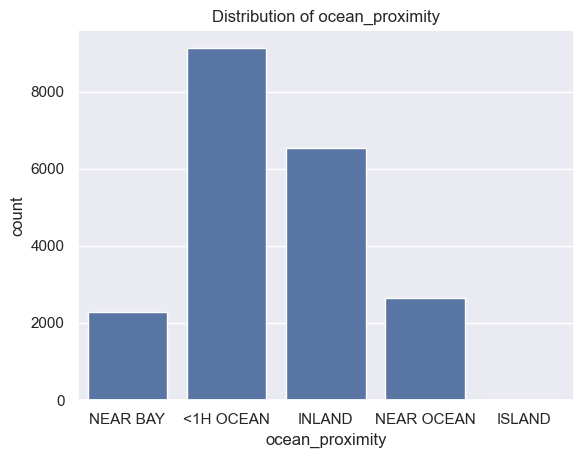

In [15]:
for col in cat_cols:
    plt.Figure(figsize=(10,3))
    sns.countplot(x=col , data = df )
    plt.title(f"Distribution of {col}")
    plt.show()

In [16]:
for col in cat_cols:
    print(df[col].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


## for num_cols

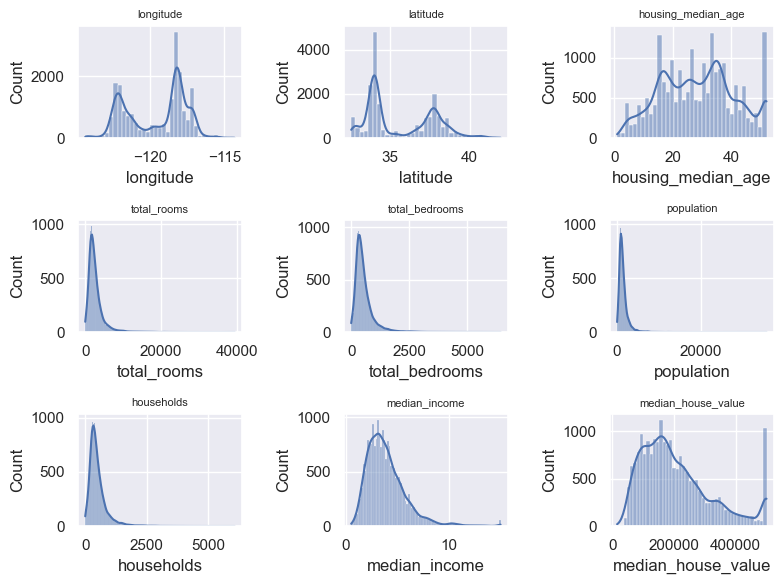

In [17]:
fig , axes = plt.subplots(3,3,figsize=(8,6))
axes = axes.flatten()
for i ,col in enumerate(num_cols):
    sns.histplot(df[col] , kde = True ,ax = axes[i] )
    axes[i].set_title(col , fontsize = 8)

plt.tight_layout()
plt.show()

## for target

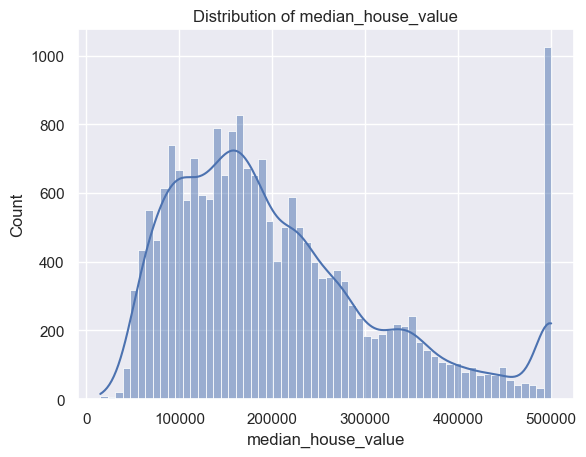

In [18]:
plt.Figure(figsize=(10,3))
sns.histplot(x=TARGET_COL , data = df , kde=True , bins=60)
plt.title(f"Distribution of {TARGET_COL}")
plt.show()

**target columns has been upper capped**

so r2_score will be low

In [19]:
df[TARGET_COL].value_counts().head()

median_house_value
500001.000    965
137500.000    122
162500.000    117
112500.000    103
187500.000     93
Name: count, dtype: int64

## outlier analysis

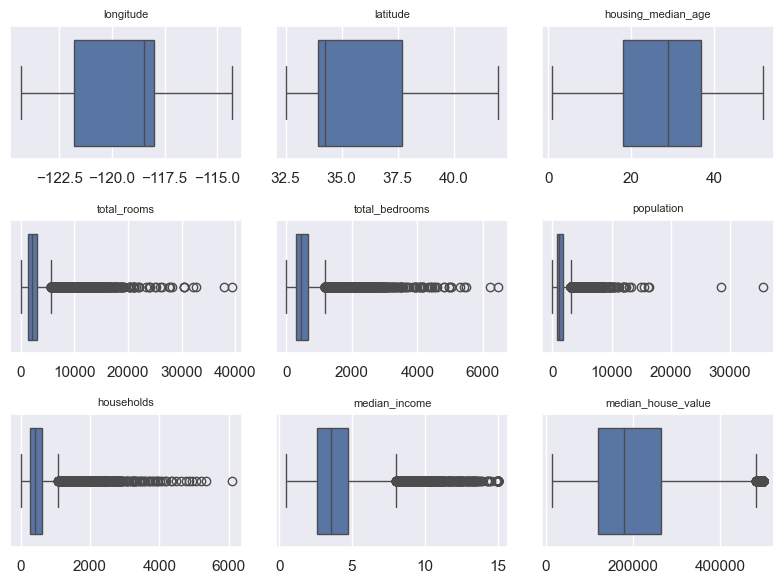

In [20]:
fig , axes = plt.subplots(3,3,figsize=(8,6))
axes = axes.flatten()
for i ,col in enumerate(num_cols):
    sns.boxplot( x= df[col]  ,ax = axes[i] )
    axes[i].set_title(col , fontsize = 8)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

## correlation heatmap

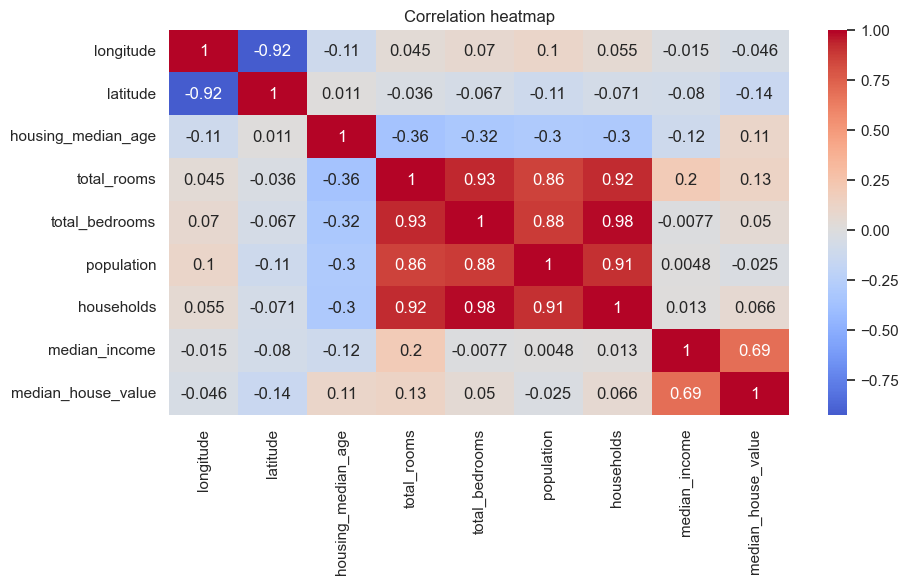

In [21]:
plt.figure(figsize = (10,5))
sns.heatmap(
    df[num_cols].corr(),
    annot = True,
    cmap = 'coolwarm',
    center = 0
)
plt.title("Correlation heatmap")
plt.show()

45 minutes

# Data Preprocessing

## train_test_split

In [47]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

In [48]:
X_train, X_test, y_train, y_test = train_test_split( X,
                                                     y, 
                                                     test_size=0.2, 
                                                     random_state=RANDOM_STATE)

## Preprocessing Pipeline

In [49]:
numeric_transformer = Pipeline(
    steps =[
    ('Imputer',SimpleImputer(strategy='median')),
    ('Scaler',StandardScaler())
]
)

In [50]:
categorical_transformer = Pipeline(
    steps = [
    ('Imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
]
)

In [51]:
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

In [52]:
preprocess = ColumnTransformer(
    transformers =[
        ('num',numeric_transformer,num_features),
        ('cat',categorical_transformer,cat_cols)
    ]
)

# Baseline Model

In [53]:
baseline_pipe = Pipeline(
    steps=[
        ('preprocess',preprocess),
        ('model',LinearRegression())
    ]
)

## Preprocess the data and train the baseline model

In [54]:
baseline_pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

## Evaluation of base_line model

In [55]:
train_baseline_pred = baseline_pipe.predict(X_train)
test_baseline_pred = baseline_pipe.predict(X_test)

## Metrics

### for trained data

In [56]:
root_mean_squared_error(y_train , train_baseline_pred)

68433.93736666226

In [57]:
r2_score(y_train,train_baseline_pred)

0.6496648627123224

### for test data

In [58]:
r2_score(y_test,test_baseline_pred)

0.6254382675296266

In [59]:
root_mean_squared_error(y_test,test_baseline_pred)

70059.19333925015

# Model Selection and Optimization


In [60]:
models ={
    'LinearRegression':LinearRegression(),
    'Ridge':Ridge(random_state=RANDOM_STATE),
    "Lasso":Lasso(random_state=RANDOM_STATE,max_iter=10000),
    "RandomForest":RandomForestRegressor(),
    "HistGB":HistGradientBoostingRegressor()
}

In [61]:
k = 5
cv = KFold(n_splits=k , shuffle=True,random_state=RANDOM_STATE)

In [62]:
scoring={
    'rmse':'neg_root_mean_squared_error',
    'mse':'neg_mean_absolute_error',
    'r2':'r2'

}

In [ ]:
rows = []

for name , model in models.items():
     pipe = Pipeline(
          steps=[
                ('preprocess',preprocess),
                ('model',model)
          ]
     )
     scores = cross_validate(pipe,X_train, y_train , cv = cv , scoring=scoring , n_jobs = -1)
     rows.append(
          {"model" : name,
           "cv_rmse" :scores['test_rmse'].mean())

SyntaxError: closing parenthesis ')' does not match opening parenthesis '{' on line 12 (2473683519.py, line 13)